# Forecast error, net value and friction sensitivity
Frozen study eed008040d6c6d18. Post-study evidence review, hypothetical fills.


In [1]:
from pathlib import Path
import os,sys,html
root=Path.cwd()
if not (root/'carry').exists():root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
def show_svg(svg):
    if '_emit_data' in globals():_emit_data({'image/svg+xml':svg})
    else:
        from IPython.display import display,SVG
        display(SVG(svg))
def show_table(headers,rows):
    markup='<table><thead><tr>'+''.join('<th>'+html.escape(str(v))+'</th>' for v in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)+'</tbody></table>'
    if '_emit_data' in globals():_emit_data({'text/html':markup})
    else:
        from IPython.display import display,HTML
        display(HTML(markup))


## Question and temporal contract
Does a forecast improve next-settlement funding prediction and net strategy economics? Fixed families: last rate, nine-period mean and ridge AR(1). Past-only training starts at 24 observations and uses at most 90. The threshold is fixed at 0.5 bps. Development, validation and holdout are reported separately; this consumed holdout cannot be reused as untouched.

In [2]:
import csv,json,math,statistics
from pathlib import Path
from carry.figures import lines,bars
from carry.engine import Config,replay,stress_case
from carry.run import sample,forecast_comparison,summarize,golden_case

def read_csv(name):
    with Path(name).open() as f:return list(csv.DictReader(f))


In [3]:
fixture=sample('ETHUSDT')[:80]
predictions=forecast_comparison(fixture)
assert all(p['training_end']<p['timestamp'] for p in predictions)
mutated=[dict(r) for r in fixture]
for r in mutated[60:]:r['funding']+=.01
a=forecast_comparison(mutated)
assert [p for p in predictions if p['timestamp']<fixture[60]['timestamp']]==[p for p in a if p['timestamp']<fixture[60]['timestamp']]
print('Past-only cutoffs and a future-data mutation check passed on the deterministic fixture.')

Past-only cutoffs and a future-data mutation check passed on the deterministic fixture.


In [4]:
errors=read_csv('artifacts/market/forecast_errors.csv')
show_table(['Asset','Partition','Model','n','MAE (bps)','RMSE (bps)'],[[r['symbol'],r['partition'],r['model'],r['n'],round(float(r['mae'])*10000,4),round(float(r['rmse'])*10000,4)] for r in errors])

Asset,Partition,Model,n,MAE (bps),RMSE (bps)
BTCUSDT,development,last_rate,519,0.334,0.4244
BTCUSDT,development,rolling_mean,519,0.2918,0.3665
BTCUSDT,development,ridge_ar1,519,0.3058,0.3809
BTCUSDT,validation,last_rate,276,0.212,0.3076
BTCUSDT,validation,rolling_mean,276,0.1988,0.2759
BTCUSDT,validation,ridge_ar1,276,0.2446,0.3064
BTCUSDT,holdout,last_rate,276,0.3036,0.3916
BTCUSDT,holdout,rolling_mean,276,0.2868,0.3466
BTCUSDT,holdout,ridge_ar1,276,0.3079,0.3749
ETHUSDT,development,last_rate,519,0.3521,0.4587


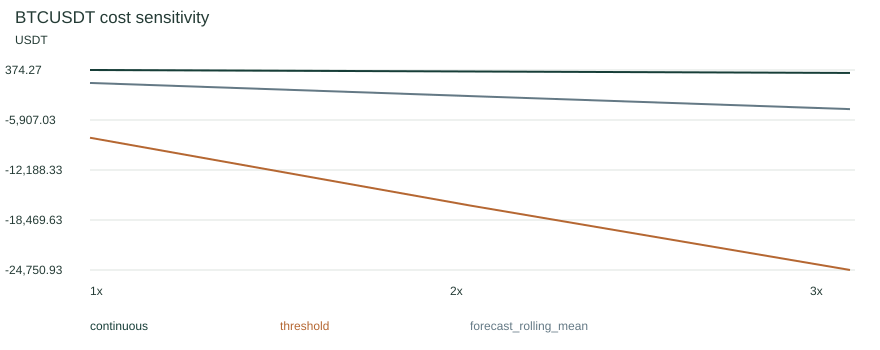

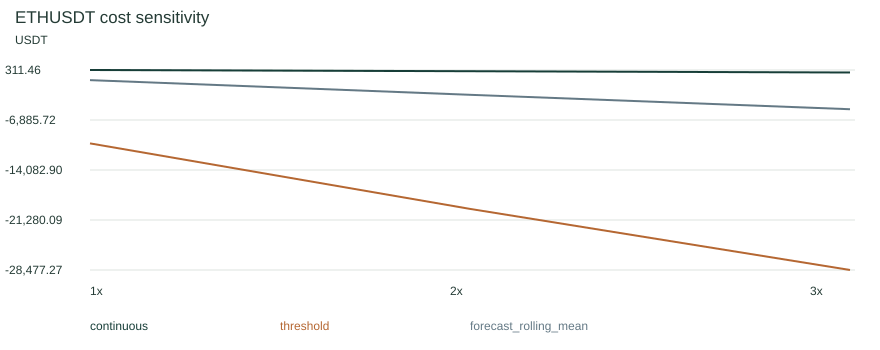

In [5]:
cost=read_csv('artifacts/market/cost_sensitivity.csv')
for symbol in ('BTCUSDT','ETHUSDT'):
    group={p:[r for r in cost if r['symbol']==symbol and r['partition']=='holdout' and r['policy']==p] for p in ('continuous','threshold','forecast_rolling_mean')}
    show_svg(lines(symbol+' cost sensitivity',['1x','2x','3x'],{k:[float(r['net_pnl']) for r in v] for k,v in group.items()}))

In [6]:
intervals=read_csv('artifacts/market/paired_uncertainty.csv')
show_table(['Asset','Policy minus benchmark','Observed P&L difference','95% block low','95% block high'],[[r['symbol'],r['policy']+' - '+r['benchmark'],*[round(float(r[k]),2) for k in ('paired_pnl_difference','block_bootstrap_low','block_bootstrap_high')]] for r in intervals if r['partition']=='holdout'])
print('Paired daily increments; 7-day moving blocks, 2,000 draws, seed 20261124.')

Asset,Policy minus benchmark,Observed P&L difference,95% block low,95% block high
BTCUSDT,threshold - continuous,-8511.67,-10603.4,-6433.4
BTCUSDT,forecast_rolling_mean - forecast_last_rate,6882.02,4692.99,8969.58
BTCUSDT,forecast_ridge_ar1 - forecast_last_rate,3803.16,1411.76,6623.61
ETHUSDT,threshold - continuous,-10563.9,-12721.41,-8961.71
ETHUSDT,forecast_rolling_mean - forecast_last_rate,9105.32,7280.5,11643.45
ETHUSDT,forecast_ridge_ar1 - forecast_last_rate,6393.76,3299.87,8917.26


Paired daily increments; 7-day moving blocks, 2,000 draws, seed 20261124.


In [7]:
delay=read_csv('artifacts/market/delay_sensitivity.csv')
show_table(['Asset','Policy','Delay (events)','Holdout net P&L'],[[r['symbol'],r['policy'],r['delay_events'],round(float(r['net_pnl']),2)] for r in delay if r['partition']=='holdout' and r['policy'] in ('continuous','threshold')])

Asset,Policy,Delay (events),Holdout net P&L
BTCUSDT,continuous,1,374.27
BTCUSDT,continuous,2,366.44
BTCUSDT,continuous,3,367.78
BTCUSDT,threshold,1,-8137.4
BTCUSDT,threshold,2,-7250.83
BTCUSDT,threshold,3,-8082.12
ETHUSDT,continuous,1,311.46
ETHUSDT,continuous,2,301.88
ETHUSDT,continuous,3,301.16
ETHUSDT,threshold,1,-10252.43


## Interpretation
Compare error and economics separately. ETH ridge improves forecast MAE relative to the mean but has worse net threshold-strategy economics. Smoothing improves on the naive last-rate filter but does not beat continuous carry in this holdout. Continuous carry itself becomes fragile when costs scale up. The block intervals describe this observed regime; they do not adjust for model search or execution misspecification.

## Conclusion and artifacts
The incremental trading-benefit gate fails against the simpler continuous benchmark. No hyperparameter or threshold is revised here. Sources: frozen `forecast_errors.csv`, `cost_sensitivity.csv`, `delay_sensitivity.csv`, `paired_uncertainty.csv`. Future cost-aware rules require a new protocol and new evidence.